In [29]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.iolib.summary2 import summary_col
from pathlib import Path
import re

In [30]:
# locate the workspace root (folder containing .workspace-root); override with ECON_ROOT
import os
ROOT = Path(os.environ.get("ECON_ROOT") or next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / ".workspace-root").exists()))
data_dir = (ROOT / "data/survey_of_consumer_finance")
figs_dir = (ROOT / "problem-sets/ps1/figs")

df2022 = pd.read_csv(data_dir / "SCFP2022.csv")
df2019 = pd.read_csv(data_dir / "SCFP2019.csv")
df2016 = pd.read_csv(data_dir / "SCFP2016.csv")

df2022["YEAR"] = 2022
df2019["YEAR"] = 2019
df2016["YEAR"] = 2016


/var/folders/9b/4f2bxvvd1mj1hdx98fkh1lcm0000gn/T/ipykernel_88998/4222665729.py:8: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df2022["YEAR"] = 2022
/var/folders/9b/4f2bxvvd1mj1hdx98fkh1lcm0000gn/T/ipykernel_88998/4222665729.py:9: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df2019["YEAR"] = 2019
/var/folders/9b/4f2bxvvd1mj1hdx98fkh1lcm0000gn/T/ipykernel_88998/4222665729.py:10: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Cons

In [31]:
# Definitions required by quartic_regression and regression_latex
dollar_vars = ["WAGEINC", "LIQ", "NETWORTH"]
base_year = 2022
CPI = {2016: 240.007, 2019: 255.657, 2022: 292.655}
deflator = {y: CPI[base_year] / CPI[y] for y in CPI}

edu_labels = ["Less than high school", "High school or GED",
              "Some college or associate", "Bachelor's degree or more"]

# EDUC codes 1-14 collapsed to four groups; verify against the codebook (cf. EDCL).
edu_map = {**{k: edu_labels[0] for k in range(1, 8)}, 8: edu_labels[1],
           **{k: edu_labels[2] for k in (9, 10, 11)},
           **{k: edu_labels[3] for k in (12, 13, 14)}}

# Race is harmonized: Asian (code 4, 2022 only) is folded into Other (code 5).
labels = {"HHSEX": {1: "Male", 2: "Female"},
          "RACE": {1: "White non-Hispanic",
                   2: "Black/African American",
                   3: "Hispanic/Latino",
                   5: "Other (incl. Asian)"}}

def deflated(df, year):
    d = df.copy()
    for v in dollar_vars:
        d[v] = d[v] * deflator[year]
    return d



In [32]:
df2019 = deflated(df2019, 2019)
df2016 = deflated(df2016, 2016)

jointpooled = pd.concat(
    [df2022, df2019, df2016],
    axis=0,
    ignore_index=True
)

In [33]:
def weighted_median(group, variable):
    data = group[[variable, "WGT"]].dropna()
    data = data.sort_values(variable)

    cumulative_weight = data["WGT"].cumsum()
    cutoff = data["WGT"].sum() / 2

    return data.loc[cumulative_weight >= cutoff, variable].iloc[0]


def weighted_share(group, variable, values):
    data = group[[variable, "WGT"]].dropna()

    if not isinstance(values, (list, tuple, set)):
        values = [values]

    return (
        data.loc[data[variable].isin(values), "WGT"].sum()
        / data["WGT"].sum()
    )


def create_profile(df, year, group_variable=None):

    group_cols = ["AGE"] if group_variable is None else ["AGE", group_variable]

    profile = df.groupby(
        group_cols,
        observed=True
    ).apply(
        lambda g: pd.Series({
            "labor_income": weighted_median(g, "WAGEINC"),
            "wealth": weighted_median(g, "NETWORTH"),
            "liquid_wealth": weighted_median(g, "LIQ"),
            "n_obs": g["LIQ"].notna().sum(),
            "weight": g.loc[g["LIQ"].notna(), "WGT"].sum()
        }),
        include_groups=False
    )

    profile["YEAR"] = year

    return profile.reset_index()

In [34]:
def add_education_group(df):
    df = df.copy()

    df["EDUC_GROUP"] = pd.cut(
        df["EDUC"],
        bins=[-float("inf"), 5, 8, 10, float("inf")],
        labels=[
            "Less than high school",
            "High school or GED",
            "Some college or associate",
            "Bachelor's degree or more"
        ],
        right=True
    )

    return df

df2022 = add_education_group(df2022)
df2019 = add_education_group(df2019)
df2016 = add_education_group(df2016)
jointpooled = add_education_group(jointpooled)

profile_educ2022 = create_profile(df2022, 2022, "EDUC_GROUP")
profile_educ2019 = create_profile(df2019, 2019, "EDUC_GROUP")
profile_educ2016 = create_profile(df2016, 2016, "EDUC_GROUP")
profile_educall = create_profile(jointpooled, 6057, "EDUC_GROUP")

profile_educ = pd.concat(
    [
        profile_educ2016,
        profile_educ2019,
        profile_educ2022,
        profile_educall
    ],
    ignore_index=True
)

In [35]:
def add_race_group(df):
    df = df.copy()

    df["RACE_GROUP"] = df["RACE"].replace({
        1: "White non-Hispanic",
        2: "Black",
        3: "Hispanic",
        4: "Other",
        5: "Other"
    })

    return df

df2022 = add_race_group(df2022)
df2019 = add_race_group(df2019)
df2016 = add_race_group(df2016)
jointpooled = add_race_group(jointpooled)



profile_race2022 = create_profile(df2022, 2022, "RACE_GROUP")
profile_race2019 = create_profile(df2019, 2019, "RACE_GROUP")
profile_race2016 = create_profile(df2016, 2016, "RACE_GROUP")
profile_raceall = create_profile(jointpooled, 6057, "RACE_GROUP")

profile_race = pd.concat(
    [
        profile_race2016,
        profile_race2019,
        profile_race2022,
        profile_raceall
    ],
    ignore_index=False
)

In [36]:
def add_sex_group(df):
    df = df.copy()
    df["HHSEX_GROUP"] = df["HHSEX"].replace({
        1: "Male",
        2: "Female",
    })

    return df

df2022 = add_sex_group(df2022)
df2019 = add_sex_group(df2019)
df2016 = add_sex_group(df2016)
jointpooled = add_sex_group(jointpooled)

profile2022 = create_profile(df2022, 2022, "HHSEX_GROUP")
profile2019 = create_profile(df2019, 2019, "HHSEX_GROUP")
profile2016 = create_profile(df2022, 2016, "HHSEX_GROUP")
profileall = create_profile(jointpooled, 6057, "HHSEX_GROUP")


profile = pd.concat(
    [
        profile2022, 
        profile2019, 
        profile2016, 
        profileall
    ],
    ignore_index=False
)

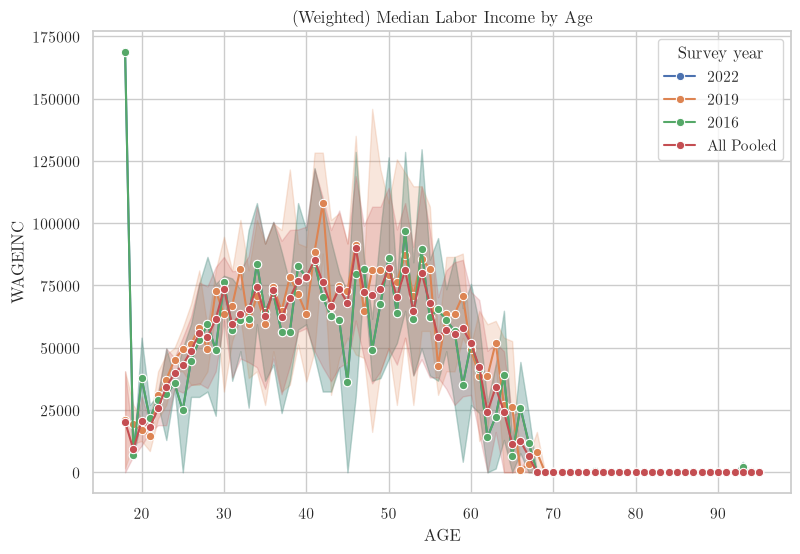

In [37]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile[
    profile["YEAR"].isin([2022, 2019, 2016, 6057])
].copy()

plot_data["YEAR"] = plot_data["YEAR"].replace({
    2022: "2022",
    2019: "2019",
    2016: "2016",
    6057: "All Pooled"
})

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="labor_income",
    hue="YEAR",
    marker="o"
)

ax.set_title("(Weighted) Median Labor Income by Age")
ax.set_xlabel("AGE")
ax.set_ylabel("WAGEINC")
ax.legend(title="Survey year")

plt.savefig(
    figs_dir / "problemset1_labor_income_by_age_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

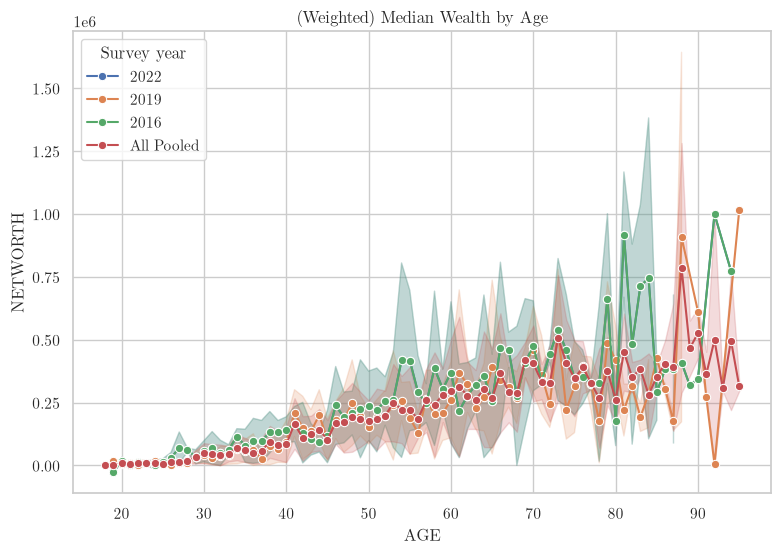

In [38]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile[
    (profile["YEAR"].isin([2022, 2019, 2016, 6057]))
    &
    (profile["n_obs"] >= 20)
].copy()

plot_data["YEAR"] = plot_data["YEAR"].replace({
    2022: "2022",
    2019: "2019",
    2016: "2016",
    6057: "All Pooled"
})

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="wealth",
    hue="YEAR",
    marker="o"
)

ax.set_title("(Weighted) Median Wealth by Age")
ax.set_xlabel("AGE")
ax.set_ylabel("NETWORTH")
ax.legend(title="Survey year")

plt.savefig(
    figs_dir / "problemset1_wealth_by_age_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

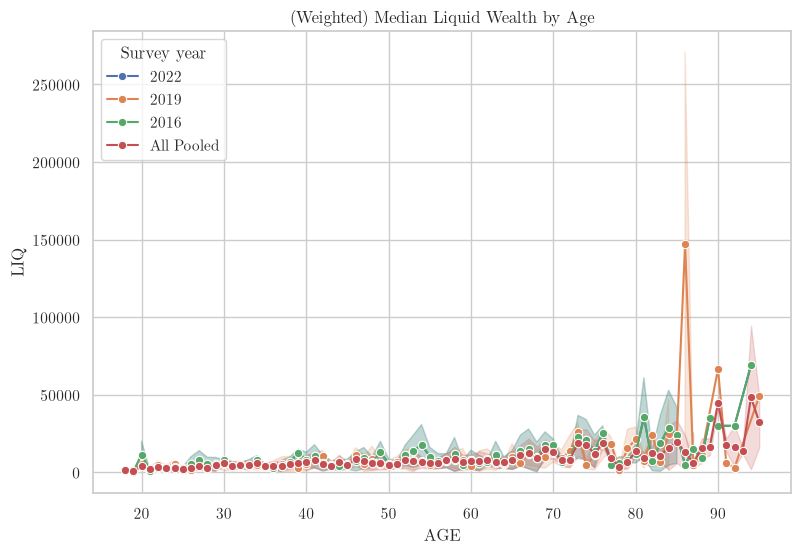

In [39]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile[
    (profile["YEAR"].isin([2022, 2019, 2016, 6057]))
    &
    (profile["n_obs"] >= 20)
].copy()

plot_data["YEAR"] = plot_data["YEAR"].replace({
    2022: "2022",
    2019: "2019",
    2016: "2016",
    6057: "All Pooled"
})

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="liquid_wealth",
    hue="YEAR",
    marker="o"
)

ax.set_title("(Weighted) Median Liquid Wealth by Age")
ax.set_xlabel("AGE")
ax.set_ylabel("LIQ")
ax.legend(title="Survey year")

plt.savefig(
    figs_dir / "problemset1_liquid_wealth_by_age_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

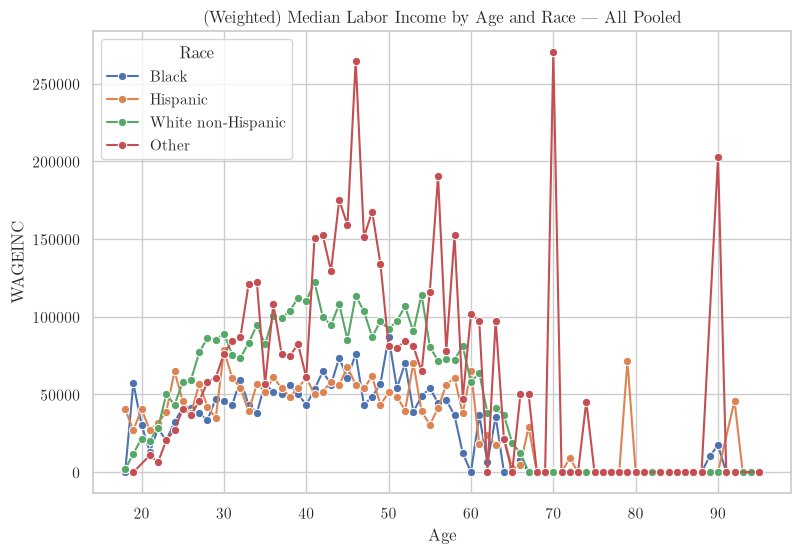

In [40]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile_race[
    profile_race["YEAR"] == 6057
].copy()

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="labor_income",
    hue="RACE_GROUP",
    marker="o"
)

ax.set_title("(Weighted) Median Labor Income by Age and Race — All Pooled")
ax.set_xlabel("Age")
ax.set_ylabel("WAGEINC")
ax.legend(title="Race")

plt.savefig(
    figs_dir / "problemset1_labor_income_by_age_race_pooled_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

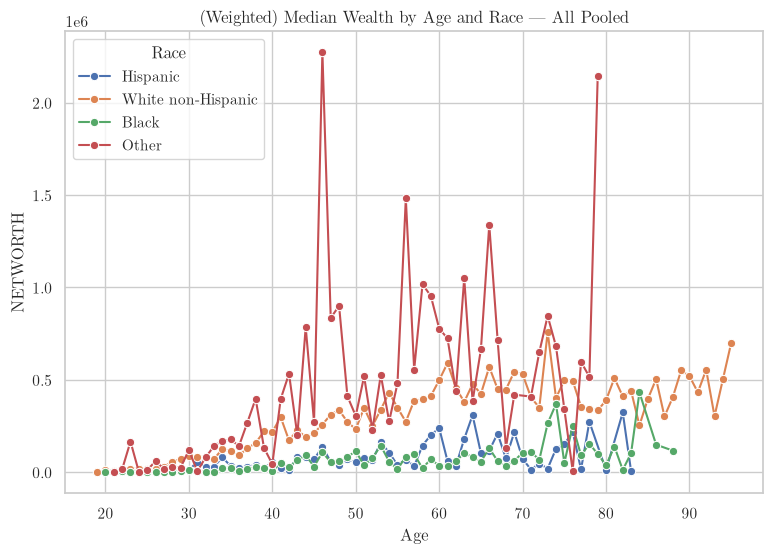

In [41]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile_race[
    (profile_race["YEAR"] == 6057) &
    (profile_race["n_obs"] >= 20)
].copy()

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="wealth",
    hue="RACE_GROUP",
    marker="o"
)

ax.set_title("(Weighted) Median Wealth by Age and Race — All Pooled")
ax.set_xlabel("Age")
ax.set_ylabel("NETWORTH")
ax.legend(title="Race")

plt.savefig(
    figs_dir / "problemset1_wealth_by_age_race_pooled_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

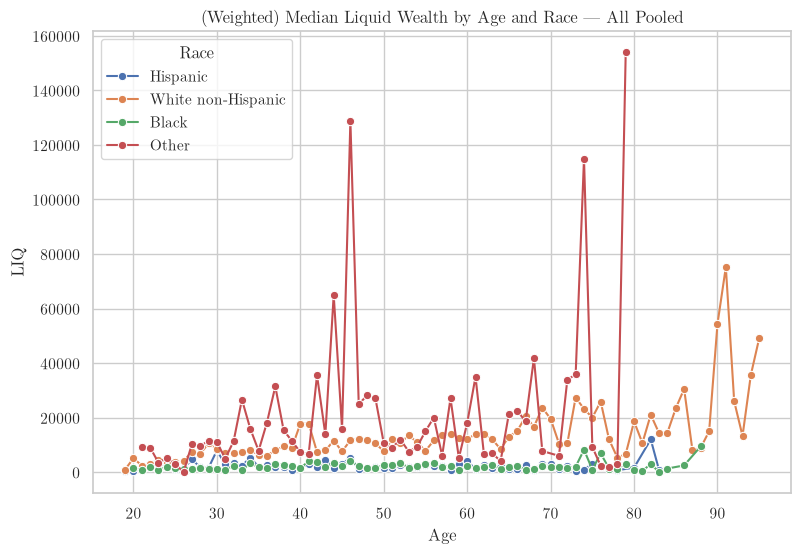

In [42]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile_race[
    (profile_race["YEAR"] == 6057) &
    (profile_race["n_obs"] >= 20)
].copy()

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="liquid_wealth",
    hue="RACE_GROUP",
    marker="o"
)

ax.set_title(
    "(Weighted) Median Liquid Wealth by Age and Race — All Pooled"
)
ax.set_xlabel("Age")
ax.set_ylabel("LIQ")
ax.legend(title="Race")

plt.savefig(
    figs_dir / "problemset1_liquid_wealth_by_age_race_pooled_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()


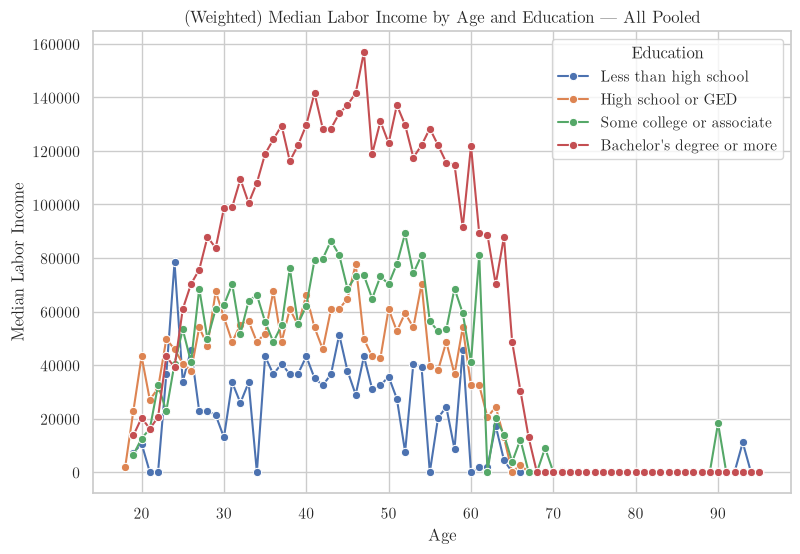

In [43]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile_educ[
    (profile_educ["YEAR"] == 6057)
].copy()

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="labor_income",
    hue="EDUC_GROUP",
    marker="o"
)

ax.set_title("(Weighted) Median Labor Income by Age and Education — All Pooled")
ax.set_xlabel("Age")
ax.set_ylabel("Median Labor Income")
ax.legend(
    title="Education",
    
)

plt.savefig(
    figs_dir / "problemset1_labor_income_by_age_education_pooled_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

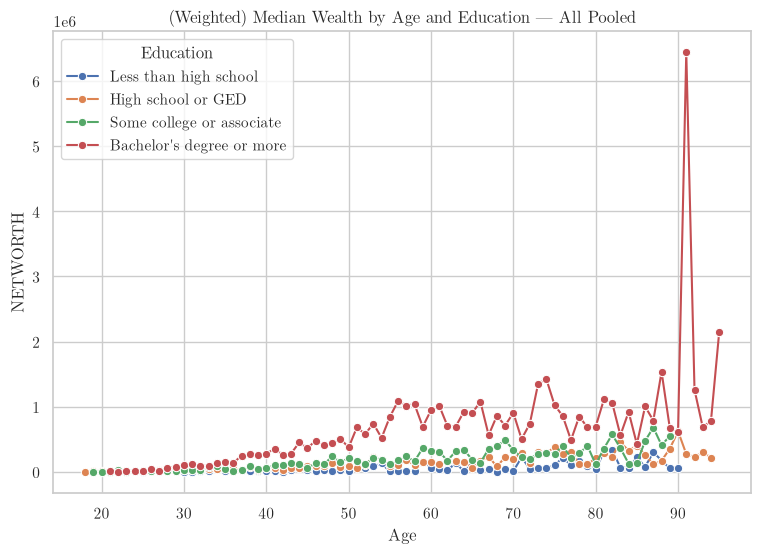

In [44]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile_educ[
    (profile_educ["YEAR"] == 6057) &
    (profile_educ["n_obs"] >= 20)
].copy()

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="wealth",
    hue="EDUC_GROUP",
    marker="o"
)

ax.set_title("(Weighted) Median Wealth by Age and Education — All Pooled")
ax.set_xlabel("Age")
ax.set_ylabel("NETWORTH")
ax.legend(
    title="Education",
    
)

plt.savefig(
    figs_dir / "problemset1_wealth_by_age_education_pooled_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

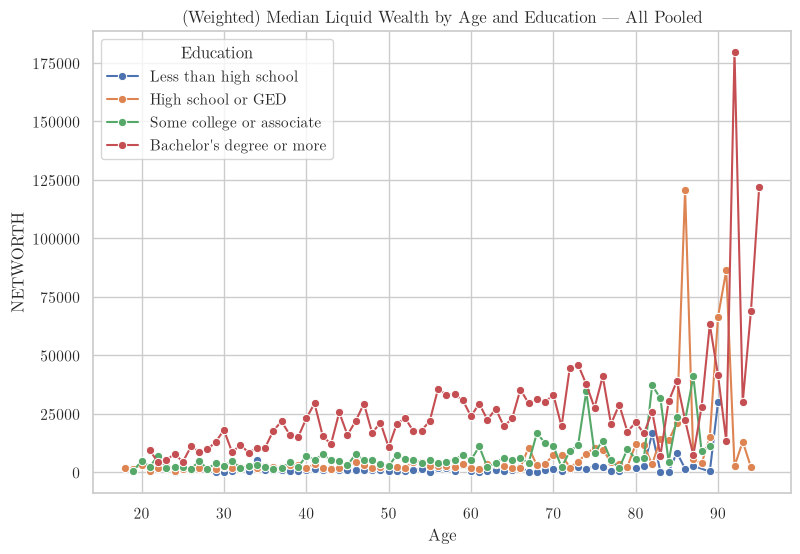

In [45]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile_educ[
    (profile_educ["YEAR"] == 6057) &
    (profile_educ["n_obs"] >= 20)
].copy()

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="liquid_wealth",
    hue="EDUC_GROUP",
    marker="o"
)

ax.set_title("(Weighted) Median Liquid Wealth by Age and Education — All Pooled")
ax.set_xlabel("Age")
ax.set_ylabel("NETWORTH")
ax.legend(
    title="Education",
    
)

plt.savefig(
    figs_dir / "problemset1_liquid_wealth_by_age_education_pooled_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

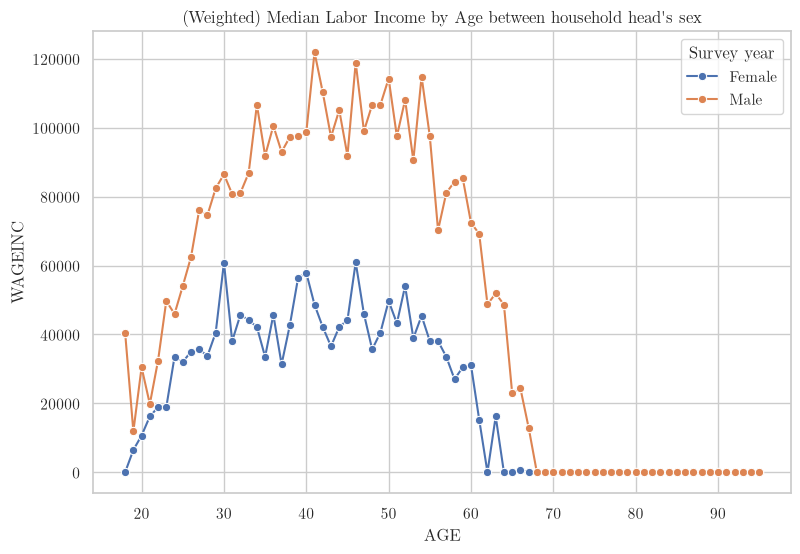

In [46]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile[
    (profile["YEAR"].isin([6057]))
    &
    (profile["n_obs"] >= 20)
].copy()

plot_data["YEAR"] = plot_data["YEAR"].replace({
    2022: "2022",
    2019: "2019",
    2016: "2016",
    6057: "All Pooled"
})

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="labor_income",
    hue="HHSEX_GROUP",
    marker="o"
)

ax.set_title("(Weighted) Median Labor Income by Age between household head's sex")
ax.set_xlabel("AGE")
ax.set_ylabel("WAGEINC")
ax.legend(title="Survey year")

plt.savefig(
    figs_dir / "problemset1_labor_income_by_age_hhsex_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

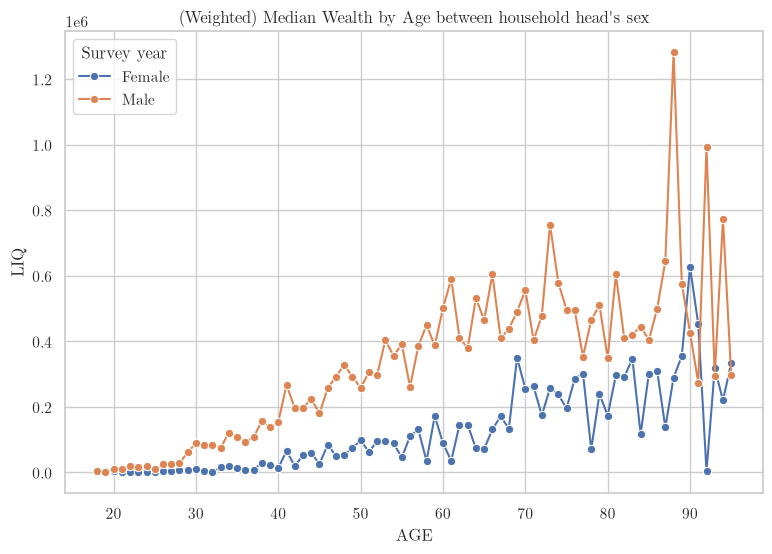

In [47]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile[
    (profile["YEAR"].isin([6057]))
    &
    (profile["n_obs"] >= 20)
].copy()

plot_data["YEAR"] = plot_data["YEAR"].replace({
    2022: "2022",
    2019: "2019",
    2016: "2016",
    6057: "All Pooled"
})

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="wealth",
    hue="HHSEX_GROUP",
    marker="o"
)

ax.set_title("(Weighted) Median Wealth by Age between household head's sex")
ax.set_xlabel("AGE")
ax.set_ylabel("LIQ")
ax.legend(title="Survey year")

plt.savefig(
    figs_dir / "problemset1_wealth_by_age_hhsex_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

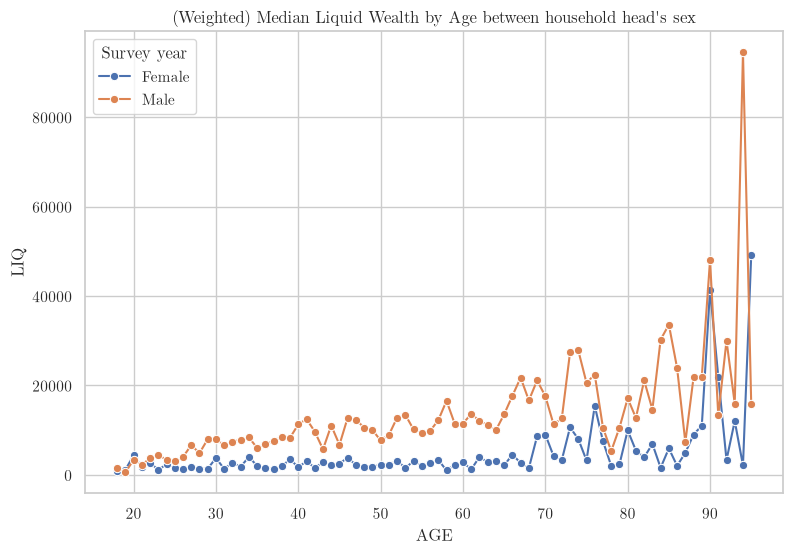

In [48]:
sns.set_theme(
    style="whitegrid",
    font="Latin Modern Roman"
)

plt.figure(figsize=(9, 6))

plot_data = profile[
    (profile["YEAR"].isin([6057]))
    &
    (profile["n_obs"] >= 20)
].copy()

plot_data["YEAR"] = plot_data["YEAR"].replace({
    2022: "2022",
    2019: "2019",
    2016: "2016",
    6057: "All Pooled"
})

ax = sns.lineplot(
    data=plot_data,
    x="AGE",
    y="liquid_wealth",
    hue="HHSEX_GROUP",
    marker="o"
)

ax.set_title("(Weighted) Median Liquid Wealth by Age between household head's sex")
ax.set_xlabel("AGE")
ax.set_ylabel("LIQ")
ax.legend(title="Survey year")

plt.savefig(
    figs_dir / "problemset1_liquid_wealth_by_age_hhsex_sfc.pdf",
    format="pdf",
    bbox_inches="tight"
)

plt.show()

In [49]:
for power in range(1, 5):
    df2022[f"age_power{power}"] = df2022["AGE"] ** power
for power in range(1, 5):
    df2019[f"age_power{power}"] = df2019["AGE"] ** power
for power in range(1, 5):
    df2016[f"age_power{power}"] = df2016["AGE"] ** power
for power in range(1, 5):
    jointpooled[f"age_power{power}"] = jointpooled["AGE"] ** power

df2022

,YY1,Y1,WGT,HHSEX,AGE,AGECL,EDUC,EDCL,MARRIED,KIDS,...,INCQRTCAT,NINCQRTCAT,YEAR,EDUC_GROUP,RACE_GROUP,HHSEX_GROUP,age_power1,age_power2,age_power3,age_power4
0,1,11,3027.956120,2,70,5,9,3,2,2,...,2,1,2022,Some college or associate,White non-Hispanic,Female,70,4900,343000,24010000
1,1,12,3054.900065,2,70,5,9,3,2,2,...,2,1,2022,Some college or associate,White non-Hispanic,Female,70,4900,343000,24010000
2,1,13,3163.637766,2,70,5,9,3,2,2,...,1,1,2022,Some college or associate,White non-Hispanic,Female,70,4900,343000,24010000
3,1,14,3166.228463,2,70,5,9,3,2,2,...,1,1,2022,Some college or associate,White non-Hispanic,Female,70,4900,343000,24010000
4,1,15,3235.624715,2,70,5,9,3,2,2,...,1,1,2022,Some college or associate,White non-Hispanic,Female,70,4900,343000,24010000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22970,4603,46031,1705.225499,2,40,2,8,2,2,2,...,2,1,2022,High school or GED,Black,Female,40,1600,64000,2560000
22971,4603,46032,1713.918975,2,40,2,8,2,2,2,...,1,1,2022,High school or GED,Black,Female,40,1600,64000,2560000
22972,4603,46033,1689.140933,2,40,2,8,2,2,2,...,2,1,2022,High school or GED,Black,Female,40,1600,64000,2560000
22973,4603,46034,1714.060239,2,40,2,8,2,2,2,...,2,1,2022,High school or GED,Black,Female,40,1600,64000,2560000


In [50]:
power_cols = ["age_power1", "age_power2", "age_power3", "age_power4"]


def quartic_regression(data, outcome, male_only=True, controls=True,
                       year_fe=False, cov_type=None):
    """WLS of `outcome` on a quartic in age, restricted to male heads (HHSEX = 1),
    with education and race/ethnicity of the head as categorical controls."""
    d = data[data["HHSEX"] == 1].copy() if male_only else data.copy()

    for k in range(1, 5):                                    # build age powers if absent
        if f"age_power{k}" not in d:
            d[f"age_power{k}"] = d["AGE"].astype(float) ** k
    X = d[power_cols].astype(float)

    if controls:
        edu = pd.Categorical(d["EDUC"].clip(lower=1).map(edu_map), categories=edu_labels)
        race = pd.Categorical(d["RACE"].replace(4, 5).map(labels["RACE"]),
                              categories=list(labels["RACE"].values()))
        C = pd.get_dummies(pd.DataFrame({"EDU": edu, "RACE": race}, index=d.index),
                           drop_first=True, dtype=float)
        X = pd.concat([X, C], axis=1)

    if year_fe:                                              # wave dummies, for pooled samples
        X = pd.concat([X, pd.get_dummies(d["YEAR"], prefix="YEAR",
                                         drop_first=True, dtype=float)], axis=1)

    X = sm.add_constant(X)
    model = sm.WLS(d[outcome], X, weights=d["WGT"])
    return model.fit(cov_type=cov_type) if cov_type else model.fit()

In [51]:
income_model2022 = quartic_regression(df2022, "WAGEINC")
income_model2019 = quartic_regression(df2019, "WAGEINC")
income_model2016 = quartic_regression(df2016, "WAGEINC")
income_modelall = quartic_regression(jointpooled, "WAGEINC")

results_table_labor_income = summary_col(
    [income_model2022, income_model2019,income_model2016,income_modelall ],
    stars=True,
        model_names=["2022", "2019", "2016", "All Pooled"],
        info_dict={
            "N": lambda x: f"{int(x.nobs)}"
        },
)
print(results_table_labor_income)


                                   2022           2019           2016        All Pooled  
-----------------------------------------------------------------------------------------
const                         473682.2129*** 433620.9229*** 469718.2989*** 464518.7264***
                              (107513.9694)  (71713.8869)   (160356.5359)  (68097.6297)  
age_power1                    -53336.7185*** -50218.0115*** -52748.8059*** -52551.5106***
                              (9089.2180)    (6185.6161)    (13850.1046)   (5832.3713)   
age_power2                    2055.9784***   1988.7693***   2050.8691***   2045.8289***  
                              (271.7016)     (188.6099)     (423.5259)     (176.6914)    
age_power3                    -29.9241***    -29.5150***    -30.0031***    -29.9870***   
                              (3.4226)       (2.4228)       (5.4582)       (2.2556)      
age_power4                    0.1439***      0.1443***      0.1448***      0.1450***     
         

In [52]:
tex = results_table_labor_income.as_latex()
tab = re.search(r"\\begin\{tabular\}.*?\\end\{tabular\}", tex, re.S).group(0)

# booktabs rules in place of \hline
parts = tab.split("\\hline")
rules = ["\\toprule"] + ["\\midrule"] * (len(parts) - 3) + ["\\bottomrule"]
tab = "".join(p + r for p, r in zip(parts, rules)) + parts[-1]

table = (
    "\\begin{table}[htbp]\n\\centering\n"
    "\\caption{Quartic regressions of labor income (WAGEINC) on age}\n"
    "\\label{tab:scf_wageinc_quartic}\n"
    "\\begin{threeparttable}\n"
    f"{tab}\n"
    "\\begin{tablenotes}\n\\footnotesize\n"
    "\\item \\textit{Notes:} Standard errors in parentheses. "
    "$^{*}p<0.1$, $^{**}p<0.05$, $^{***}p<0.01$. "
    "The last column stacks the 2016, 2019, and 2022 waves.\n"
    "\\end{tablenotes}\n\\end{threeparttable}\n\\end{table}\n"
)
print(table)

\begin{table}[htbp]
\centering
\caption{Quartic regressions of labor income (WAGEINC) on age}
\label{tab:scf_wageinc_quartic}
\begin{threeparttable}
\begin{tabular}{lllll}
\toprule
                               & 2022           & 2019           & 2016           & All Pooled      \\
\midrule
const                          & 473682.2129*** & 433620.9229*** & 469718.2989*** & 464518.7264***  \\
                               & (107513.9694)  & (71713.8869)   & (160356.5359)  & (68097.6297)    \\
age\_power1                    & -53336.7185*** & -50218.0115*** & -52748.8059*** & -52551.5106***  \\
                               & (9089.2180)    & (6185.6161)    & (13850.1046)   & (5832.3713)     \\
age\_power2                    & 2055.9784***   & 1988.7693***   & 2050.8691***   & 2045.8289***    \\
                               & (271.7016)     & (188.6099)     & (423.5259)     & (176.6914)      \\
age\_power3                    & -29.9241***    & -29.5150***    & -30.0031***    & -29.9

In [53]:
wealth_model2022 = quartic_regression(df2022, "NETWORTH")
wealth_model2019 = quartic_regression(df2019, "NETWORTH")
wealth_model2016 = quartic_regression(df2016, "NETWORTH")
wealth_modelall = quartic_regression(jointpooled, "NETWORTH")

results_table_labor_wealth = summary_col(
    [wealth_model2022, wealth_model2019,wealth_model2016,wealth_modelall ],
    stars=True,
        model_names=["2022", "2019", "2016", "All Pooled"],
        info_dict={
            "N": lambda x: f"{int(x.nobs)}"
        },
)
print(results_table_labor_wealth)


                                    2022            2019            2016          All Pooled   
-----------------------------------------------------------------------------------------------
const                         9065042.8218**  9807397.7372*** 14195540.6204*** 11050564.9121***
                              (4044995.8384)  (3287642.9428)  (3668130.9052)   (2086291.7285)  
age_power1                    -889268.5447*** -955491.0249*** -1341112.4621*** -1064770.4125***
                              (341963.4593)   (283572.6532)   (316818.9962)    (178685.0458)   
age_power2                    27113.1460***   29370.8883***   41052.2770***    32622.9227***   
                              (10222.2247)    (8646.6102)     (9688.0892)      (5413.2557)     
age_power3                    -323.6497**     -349.3822***    -499.1091***     -392.3859***    
                              (128.7679)      (111.0711)      (124.8560)       (69.1053)       
age_power4                    1.3543** 

In [54]:
tex = results_table_labor_wealth.as_latex()
tab = re.search(r"\\begin\{tabular\}.*?\\end\{tabular\}", tex, re.S).group(0)

# booktabs rules in place of \hline
parts = tab.split("\\hline")
rules = ["\\toprule"] + ["\\midrule"] * (len(parts) - 3) + ["\\bottomrule"]
tab = "".join(p + r for p, r in zip(parts, rules)) + parts[-1]

table = (
    "\\begin{table}[htbp]\n\\centering\n"
    "\\caption{Quartic regressions of wealth (NETWORTH) on age}\n"
    "\\label{tab:scf_networth_quartic}\n"
    "\\begin{threeparttable}\n"
    f"{tab}\n"
    "\\begin{tablenotes}\n\\footnotesize\n"
    "\\item \\textit{Notes:} Standard errors in parentheses. "
    "$^{*}p<0.1$, $^{**}p<0.05$, $^{***}p<0.01$. "
    "The last column stacks the 2016, 2019, and 2022 waves.\n"
    "\\end{tablenotes}\n\\end{threeparttable}\n\\end{table}\n"
)
print(table)

\begin{table}[htbp]
\centering
\caption{Quartic regressions of wealth (NETWORTH) on age}
\label{tab:scf_networth_quartic}
\begin{threeparttable}
\begin{tabular}{lllll}
\toprule
                               & 2022            & 2019            & 2016             & All Pooled        \\
\midrule
const                          & 9065042.8218**  & 9807397.7372*** & 14195540.6204*** & 11050564.9121***  \\
                               & (4044995.8384)  & (3287642.9428)  & (3668130.9052)   & (2086291.7285)    \\
age\_power1                    & -889268.5447*** & -955491.0249*** & -1341112.4621*** & -1064770.4125***  \\
                               & (341963.4593)   & (283572.6532)   & (316818.9962)    & (178685.0458)     \\
age\_power2                    & 27113.1460***   & 29370.8883***   & 41052.2770***    & 32622.9227***     \\
                               & (10222.2247)    & (8646.6102)     & (9688.0892)      & (5413.2557)       \\
age\_power3                    & -323.6497**     & 

In [55]:
liquid_wealth_model2022 = quartic_regression(df2022, "LIQ")
liquid_wealth_model2019 = quartic_regression(df2019, "LIQ")
liquid_wealth_model2016 = quartic_regression(df2016, "LIQ")
liquid_wealth_modelall = quartic_regression(jointpooled, "LIQ")

results_table_labor_liquid_wealth = summary_col(
    [liquid_wealth_model2022, liquid_wealth_model2019, liquid_wealth_model2016, liquid_wealth_modelall ],
    stars=True,
        model_names=["2022", "2019", "2016", "All Pooled"],
        info_dict={
            "N": lambda x: f"{int(x.nobs)}"
        },
)
print(results_table_labor_liquid_wealth)


                                   2022           2019           2016        All Pooled  
-----------------------------------------------------------------------------------------
const                         117837.8934    348890.4556*   590412.2176*** 349883.1194** 
                              (330394.8110)  (192128.1592)  (195750.8953)  (137137.5190) 
age_power1                    -15688.3676    -35146.4500**  -58036.7030*** -35945.4919***
                              (27931.5374)   (16571.8397)   (16907.1398)   (11745.4446)  
age_power2                    516.1742       1096.7260**    1824.3427***   1132.2495***  
                              (834.9502)     (505.3034)     (517.0078)     (355.8277)    
age_power3                    -5.9829        -13.1271**     -22.6473***    -13.7082***   
                              (10.5177)      (6.4909)       (6.6630)       (4.5425)      
age_power4                    0.0234         0.0538*        0.0980***      0.0573***     
         

In [56]:
tex = results_table_labor_liquid_wealth.as_latex()
tab = re.search(r"\\begin\{tabular\}.*?\\end\{tabular\}", tex, re.S).group(0)

# booktabs rules in place of \hline
parts = tab.split("\\hline")
rules = ["\\toprule"] + ["\\midrule"] * (len(parts) - 3) + ["\\bottomrule"]
tab = "".join(p + r for p, r in zip(parts, rules)) + parts[-1]

table = (
    "\\begin{table}[htbp]\n\\centering\n"
    "\\caption{Quartic regressions of liquid wealth (LIQ) on age}\n"
    "\\label{tab:scf_liq_quartic}\n"
    "\\begin{threeparttable}\n"
    f"{tab}\n"
    "\\begin{tablenotes}\n\\footnotesize\n"
    "\\item \\textit{Notes:} Standard errors in parentheses. "
    "$^{*}p<0.1$, $^{**}p<0.05$, $^{***}p<0.01$. "
    "The last column stacks the 2016, 2019, and 2022 waves.\n"
    "\\end{tablenotes}\n\\end{threeparttable}\n\\end{table}\n"
)
print(table)

\begin{table}[htbp]
\centering
\caption{Quartic regressions of liquid wealth (LIQ) on age}
\label{tab:scf_liq_quartic}
\begin{threeparttable}
\begin{tabular}{lllll}
\toprule
                               & 2022           & 2019           & 2016           & All Pooled      \\
\midrule
const                          & 117837.8934    & 348890.4556*   & 590412.2176*** & 349883.1194**   \\
                               & (330394.8110)  & (192128.1592)  & (195750.8953)  & (137137.5190)   \\
age\_power1                    & -15688.3676    & -35146.4500**  & -58036.7030*** & -35945.4919***  \\
                               & (27931.5374)   & (16571.8397)   & (16907.1398)   & (11745.4446)    \\
age\_power2                    & 516.1742       & 1096.7260**    & 1824.3427***   & 1132.2495***    \\
                               & (834.9502)     & (505.3034)     & (517.0078)     & (355.8277)      \\
age\_power3                    & -5.9829        & -13.1271**     & -22.6473***    & -13.7082*** 

In [62]:
def predict_profile(res, age_grid, controls_at="mean"):
    """Fitted values over an age grid from a quartic WLS result.
    controls_at = "mean": non-age regressors held at their weighted sample means.
    controls_at = "reference": non-age regressors set to 0 (omitted categories)."""
    names = res.model.exog_names
    exog = pd.DataFrame(res.model.exog, columns=names)
    w = np.asarray(res.model.weights)

    grid = pd.DataFrame(index=age_grid, columns=names, dtype=float)
    for c in names:
        grid[c] = np.average(exog[c], weights=w) if controls_at == "mean" else 0.0
    grid["const"] = 1.0
    for k in range(1, 5):
        grid[f"age_power{k}"] = age_grid.astype(float) ** k
    return pd.Series(res.predict(grid[names]).to_numpy(), index=age_grid)



In [63]:
model_map = {
    "2022": {"WAGEINC": income_model2022, "NETWORTH": wealth_model2022, "LIQ": liquid_wealth_model2022},
    "2019": {"WAGEINC": income_model2019, "NETWORTH": wealth_model2019, "LIQ": liquid_wealth_model2019},
    "2016": {"WAGEINC": income_model2016, "NETWORTH": wealth_model2016, "LIQ": liquid_wealth_model2016},
    "All Pooled": {"WAGEINC": income_modelall, "NETWORTH": wealth_modelall, "LIQ": liquid_wealth_modelall},
}

profile_frames = {"2022": profile2022, "2019": profile2019,
                  "2016": profile2016, "All Pooled": profileall}

hat_names = {"WAGEINC": "labor_income_hat",
             "NETWORTH": "wealth_hat",
             "LIQ": "liquid_wealth_hat"}

age_grid = np.arange(jointpooled["AGE"].min(), jointpooled["AGE"].max() + 1)

for name, prof in profile_frames.items():
    for var, res in model_map[name].items():
        prof[hat_names[var]] = predict_profile(res, age_grid)

In [64]:
profile2022

,AGE,HHSEX_GROUP,labor_income,wealth,liquid_wealth,n_obs,weight,YEAR,labor_income_hat,wealth_hat,liquid_wealth_hat
0,18,Male,168622.244490,24900.0,3000.0,5.0,16820.957000,2022,NaN,NaN,NaN
1,19,Female,6485.470942,-27350.0,150.0,20.0,138950.003630,2022,NaN,NaN,NaN
2,19,Male,7134.018036,-1119.0,230.0,15.0,251743.654782,2022,NaN,NaN,NaN
3,20,Female,21618.236473,4430.0,2880.0,25.0,256443.175757,2022,NaN,NaN,NaN
4,20,Male,54045.591182,32600.0,20100.0,20.0,213297.004565,2022,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
150,93,Male,0.000000,687000.0,30000.0,5.0,16975.053111,2022,NaN,NaN,NaN
151,94,Female,0.000000,182000.0,2000.0,10.0,158968.088777,2022,NaN,NaN,NaN
152,94,Male,0.000000,774000.0,69000.0,25.0,179835.715313,2022,NaN,NaN,NaN
153,95,Female,0.000000,4390000.0,10000.0,5.0,9440.881550,2022,NaN,NaN,NaN
